# Neural Networks from First Principles, with Keras

A guided notebook that covers:

1. What a neural network is, its main types, and where it is used
2. Why neural network knowledge is essential for understanding the Generative AI landscape
3. The building blocks of a network, and the key terms (epoch, batch, learning rate and others) explained **before** any modelling
4. Activation functions, with formulas, plots and examples
5. Loss functions for regression, binary classification and multi-class classification, with worked numbers
6. A complete Keras example for **regression**
7. A complete Keras example for **binary classification**

**How to use this notebook:** run the cells from top to bottom. Every code cell is preceded by a short explanation, and the important lines carry comments.

**Requirements:** Python 3.9 or newer with `numpy`, `pandas`, `matplotlib`, `scikit-learn` and `tensorflow` (which includes Keras). If something is missing, uncomment and run the install line in the next cell.

In [1]:
# Uncomment the next line if packages are missing, then restart the kernel.
# !pip install numpy pandas matplotlib scikit-learn tensorflow

---
# Part 1. Concepts

## 1.1 What is a neural network?

A **neural network** is a mathematical function built from many small units called **neurons**, arranged in **layers**. Each neuron does three simple things:

1. Multiplies each input by a **weight** (how important that input is)
2. Adds the results together with a **bias** (a baseline shift)
3. Passes the total through an **activation function** (a non-linear squashing step)

The weights and biases are not written by hand. They start as small random numbers and are **learned from data**: the network makes a prediction, a **loss function** measures how wrong it is, and an algorithm called **gradient descent** nudges the weights to reduce that loss. Repeating this many times is called **training**.

The name comes from a loose inspiration from brain cells, but a neural network is best thought of as a very flexible, adjustable function: with enough neurons and data it can approximate almost any relationship between inputs and outputs.

A one-line summary:

> inputs  ->  layers of (weighted sum + bias + activation)  ->  prediction  ->  compare with truth (loss)  ->  adjust weights  ->  repeat

## 1.2 Types of neural networks

| Type | Key idea | Typical data | Example uses |
|---|---|---|---|
| Feedforward network (MLP, "dense" network) | Fully connected layers; information flows one way, input to output | Tabular data (rows and columns) | Price prediction, credit scoring, churn |
| Convolutional neural network (CNN) | Small filters slide over a grid to detect edges, textures, shapes | Images, spectrograms | Image classification, medical imaging, face unlock |
| Recurrent network (RNN, LSTM, GRU) | Processes a sequence step by step while carrying a memory | Time series, text, audio | Forecasting, early speech and translation systems |
| Transformer | Attention lets every element of a sequence look at every other element | Text, images, audio, code | Large language models, translation, code assistants |
| Autoencoder / Variational autoencoder (VAE) | Compress the input to a small code, then reconstruct it | Any data | Anomaly detection, denoising, image generation |
| Generative adversarial network (GAN) | A generator and a discriminator compete | Mostly images | Image synthesis, data augmentation, super-resolution |
| Diffusion model | A network learns to remove noise step by step | Images, audio, video | Text-to-image tools |

This notebook builds the **feedforward network**, because it contains every idea the others reuse.

## 1.3 Applications

* **Vision:** recognising objects, reading medical scans, quality inspection in factories, self-driving perception
* **Language:** translation, summarisation, chatbots, search, spam filtering
* **Speech and audio:** voice assistants, transcription, music recommendation
* **Healthcare:** disease detection from images, protein structure prediction, drug candidate screening
* **Finance:** fraud detection, risk scoring, demand and price forecasting
* **Recommendation:** what to watch, read or buy next
* **Science and engineering:** weather modelling, materials discovery, simulation shortcuts
* **Creative work:** image, music, video and text generation

## 1.4 Why neural network knowledge matters for understanding Generative AI

Generative AI can feel like a separate world, but almost every generative system is a neural network trained with the same ingredients you will meet in this notebook. Understanding the basics lets you reason about what these systems can and cannot do, instead of treating them as magic.

1. **Every major generative model is a neural network.** Large language models are transformers. Image generators are GANs, VAEs or diffusion models. All are trained by gradient descent on a loss function.
2. **The vocabulary is shared.** Layers, weights, activations, loss, optimiser, epochs, batch size, overfitting and early stopping appear in every generative training pipeline.
3. **The loss functions you will learn here are the engines of generative models.** The table below shows the link.
4. **It explains behaviour.** Why models need huge amounts of data and compute, why they can memorise (overfit), why they sometimes produce confident but wrong output (they model probabilities of what is plausible, not truth), and why fine-tuning works (you continue training the weights).
5. **It makes you a better user and builder.** You can read model papers and documentation, choose between approaches, and debug training problems.

| Generative model | Neural network inside | Loss idea from this notebook |
|---|---|---|
| Large language model | Transformer | Multi-class cross-entropy: predict the next token out of a vocabulary of tens of thousands, using softmax |
| GAN | Generator and discriminator | The discriminator is a binary classifier trained with binary cross-entropy |
| Diffusion model | U-Net or transformer | Regression: mean squared error between predicted and true noise |
| VAE | Encoder and decoder | Reconstruction error (like MSE) plus a regularisation term |

So if you understand regression, binary classification and multi-class classification, you already understand the training signal behind most of generative AI.

---
# Part 2. Building blocks and key terms (before modelling)

## 2.1 Setup

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
print("NumPy", np.__version__)

NumPy 2.4.4


## 2.2 A single neuron in plain NumPy

Take two inputs `x1` and `x2`. The neuron computes

`z = w1*x1 + w2*x2 + b`  (the weighted sum plus bias), then `output = activation(z)`.

Here we use the **sigmoid** activation, which squashes any number into the range 0 to 1.

In [3]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

x = np.array([2.0, 1.0])      # inputs (features)
w = np.array([0.5, -1.0])     # weights: how much each input matters
b = 0.5                       # bias: a baseline shift

z = np.dot(w, x) + b          # weighted sum + bias  -> 2*0.5 + 1*(-1) + 0.5
a = sigmoid(z)                # activation

print("z (weighted sum + bias) =", z)
print("output after sigmoid    =", round(float(a), 4))

z (weighted sum + bias) = 0.5
output after sigmoid    = 0.6225


## 2.3 A tiny layer and a tiny network

A **layer** is just many neurons side by side. With matrices, a whole layer is computed at once:

`output = activation(X @ W + b)`

* `X` has shape (samples, input features)
* `W` has shape (input features, neurons in the layer)
* `b` has one bias per neuron

Below, a network with 3 inputs, a hidden layer of 4 neurons (ReLU activation) and 1 output neuron (sigmoid). Weights are random here, so the output is meaningless until the network is trained. This is exactly what happens at the start of training.

In [4]:
rng = np.random.default_rng(0)

def relu(z):
    return np.maximum(0, z)

X = rng.normal(size=(5, 3))            # 5 samples, 3 features each

W1 = rng.normal(size=(3, 4)) * 0.5     # hidden layer weights: 3 inputs -> 4 neurons
b1 = np.zeros(4)
W2 = rng.normal(size=(4, 1)) * 0.5     # output layer weights: 4 neurons -> 1 output
b2 = np.zeros(1)

hidden = relu(X @ W1 + b1)             # forward pass, layer 1
output = sigmoid(hidden @ W2 + b2)     # forward pass, layer 2

print("hidden layer output shape:", hidden.shape)
print("network output shape     :", output.shape)
print("predictions (untrained)  :", output.ravel())

n_params = W1.size + b1.size + W2.size + b2.size
print("number of learnable parameters:", n_params, "= (3*4 + 4) + (4*1 + 1)")

hidden layer output shape: (5, 4)
network output shape     : (5, 1)
predictions (untrained)  : [0.4849 0.4821 0.4841 0.4602 0.433 ]
number of learnable parameters: 21 = (3*4 + 4) + (4*1 + 1)


The count of **parameters** (weights plus biases) for a dense layer is `(inputs + 1) * neurons`. Here that is `(3+1)*4 + (4+1)*1 = 21`. Modern language models have billions of parameters, but they are built from the same pieces.

## 2.4 Key terms you need before modelling

| Term | Meaning |
|---|---|
| **Sample / feature / label (target)** | One row of data is a sample. Its input columns are features. The value we want to predict is the label or target. |
| **Training, validation and test sets** | Training data is used to learn the weights. Validation data is held back during training to check progress and tune settings. Test data is touched only once at the end to report final performance honestly. |
| **Parameter** | A value the network learns: weights and biases. |
| **Hyperparameter** | A setting you choose before training: number of layers, neurons per layer, learning rate, batch size, epochs. |
| **Forward pass** | Pushing inputs through the layers to get a prediction. |
| **Loss function** | A single number that scores how wrong the predictions are. Lower is better. Training means pushing it down. |
| **Metric** | A human-friendly score such as accuracy or mean absolute error. It is reported but not optimised directly. |
| **Gradient** | The slope of the loss with respect to each weight. It tells us which direction to move a weight to reduce the loss. |
| **Backpropagation** | The efficient method for computing all gradients by applying the chain rule backwards from the loss through the layers. |
| **Optimiser** | The rule that uses gradients to update weights. Examples: SGD, Adam. |
| **Learning rate** | The step size of each update. Too large and training diverges; too small and it crawls. |
| **Batch and batch size** | Instead of using the whole dataset for each update, we use a small slice called a batch. Batch size is the number of samples in it (for example 32). |
| **Iteration (step)** | One weight update, computed from one batch. |
| **Epoch** | One complete pass over the entire training set. If there are 282 training samples and the batch size is 32, one epoch consists of 9 steps (8 full batches and one batch of 26). |
| **Overfitting** | The model memorises training data and performs worse on new data. Seen as training loss falling while validation loss rises. |
| **Underfitting** | The model is too simple or under-trained; both training and validation loss stay high. |
| **Early stopping** | Stop training when validation loss stops improving, and keep the best weights. |
| **Normalisation / standardisation** | Rescaling features to similar ranges (for example mean 0, standard deviation 1) so training is faster and more stable. |

### Epoch, batch and steps: a worked calculation

Keras prints something like `9/9` during an epoch. The second number is the **steps per epoch**: `ceil(training samples / batch size)`.

In [5]:
n_train_samples = 282
batch_size = 32
epochs = 100

steps_per_epoch = math.ceil(n_train_samples / batch_size)
full_batches = n_train_samples // batch_size
last_batch = n_train_samples - full_batches * batch_size

print("Steps per epoch      :", steps_per_epoch)
print("Full batches         :", full_batches, "of size", batch_size)
print("Size of final batch  :", last_batch)
print("Weight updates in", epochs, "epochs:", steps_per_epoch * epochs)

Steps per epoch      : 9
Full batches         : 8 of size 32
Size of final batch  : 26
Weight updates in 100 epochs: 900


### Gradient descent in one dimension

To see what "learning" means, minimise a simple loss, `loss(w) = (w - 3)^2`. Its lowest point is at `w = 3`. The gradient (slope) is `2*(w - 3)`. Each step moves `w` against the gradient, scaled by the **learning rate**.

`w_new = w_old - learning_rate * gradient`

Try different learning rates to see why this hyperparameter matters.

In [6]:
def run_gradient_descent(lr, steps=8, w=0.0):
    history = [w]
    for _ in range(steps):
        grad = 2 * (w - 3)       # slope of the loss at the current w
        w = w - lr * grad        # move downhill
        history.append(w)
    return history

for lr in [0.1, 0.4, 1.1]:
    path = run_gradient_descent(lr)
    print(f"learning rate {lr:>4}: ", np.round(path, 3))

learning rate  0.1:  [0.    0.6   1.08  1.464 1.771 2.017 2.214 2.371 2.497]
learning rate  0.4:  [0.    2.4   2.88  2.976 2.995 2.999 3.    3.    3.   ]
learning rate  1.1:  [ 0.     6.6   -1.32   8.184 -3.221 10.465 -5.958 13.75  -9.899]


* `0.1` moves steadily toward 3.
* `0.4` gets there quickly.
* `1.1` overshoots further each time and **diverges**.

A neural network does the same thing, but for millions of weights at once, with gradients supplied by backpropagation.

---
# Part 3. Activation functions

## 3.1 Why we need them

Without an activation function, every layer is just a linear operation, and a stack of linear layers collapses into a single linear layer. The network could then only learn straight-line relationships. Activation functions add the **non-linearity** that lets networks learn curves and complex patterns. The next cell proves the collapse.

In [7]:
rng = np.random.default_rng(1)
X = rng.normal(size=(4, 3))
A = rng.normal(size=(3, 5))     # layer 1 weights (no activation)
B = rng.normal(size=(5, 2))     # layer 2 weights (no activation)

two_layers = (X @ A) @ B        # two linear layers, one after another
one_layer = X @ (A @ B)         # a single linear layer with combined weights

print("Identical results:", np.allclose(two_layers, one_layer))

Identical results: True


## 3.2 The common activation functions

| Activation | Formula | Output range | Typical use |
|---|---|---|---|
| Sigmoid | 1 / (1 + e^-z) | 0 to 1 | Output layer for **binary classification** (a probability) |
| Tanh | (e^z - e^-z) / (e^z + e^-z) | -1 to 1 | Hidden layers in older networks and recurrent networks; zero-centred |
| ReLU | max(0, z) | 0 to infinity | Default for **hidden layers**: fast and works well |
| Leaky ReLU | z if z > 0, else 0.01*z | -infinity to infinity | ReLU variant that avoids "dead" neurons |
| Softmax | e^zi / sum of e^zj | 0 to 1, sums to 1 | Output layer for **multi-class classification** |
| Linear (none) | z | -infinity to infinity | Output layer for **regression** |

Notes:

* **Vanishing gradients:** sigmoid and tanh flatten out for large positive or negative inputs, so gradients become tiny and learning stalls in deep networks. ReLU avoids this for positive inputs.
* **Dying ReLU:** a ReLU neuron that always receives negative input outputs 0 and stops learning. Leaky ReLU keeps a small slope for negative inputs.

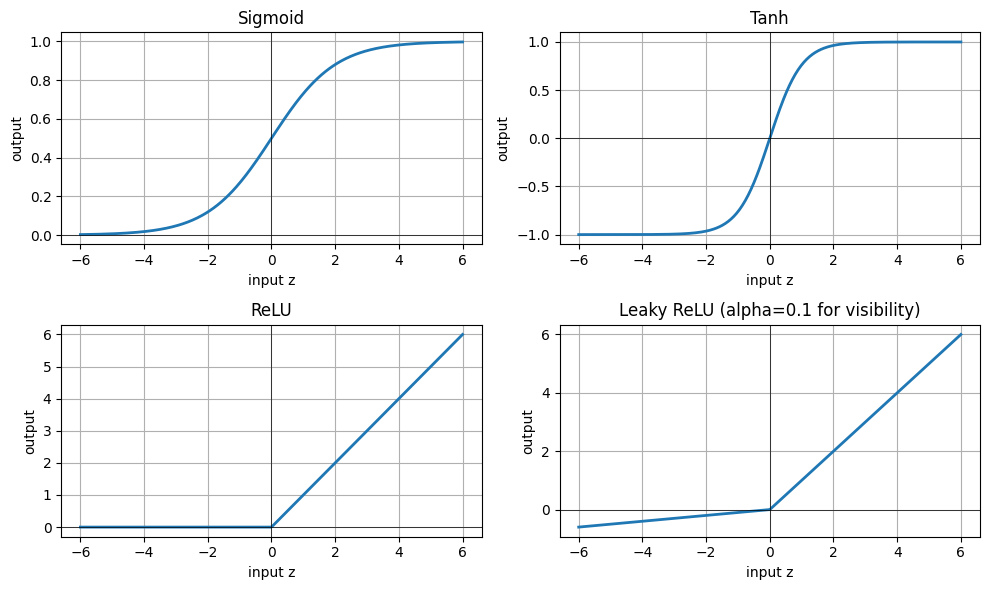

In [8]:
def tanh(z):
    return np.tanh(z)

def leaky_relu(z, alpha=0.01):
    return np.where(z > 0, z, alpha * z)

z = np.linspace(-6, 6, 400)

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (name, fn) in zip(axes.ravel(), [("Sigmoid", sigmoid), ("Tanh", tanh), ("ReLU", relu), ("Leaky ReLU (alpha=0.1 for visibility)", lambda v: leaky_relu(v, 0.1))]):
    ax.plot(z, fn(z), linewidth=2)
    ax.axhline(0, color="black", linewidth=0.5)
    ax.axvline(0, color="black", linewidth=0.5)
    ax.set_title(name)
    ax.set_xlabel("input z")
    ax.set_ylabel("output")
plt.tight_layout()
plt.show()

## 3.3 Softmax with a worked example

Softmax turns a vector of raw scores (called **logits**) into probabilities that add up to 1. It is used when exactly one class is correct among several (for example digits 0 to 9, or the next word out of a vocabulary).

Steps: exponentiate each score, then divide by the sum of all the exponentials.

In [9]:
def softmax(logits):
    shifted = logits - np.max(logits)      # subtract the max for numerical stability (does not change the result)
    exps = np.exp(shifted)
    return exps / exps.sum()

logits = np.array([2.0, 1.0, 0.1])         # raw scores for classes A, B, C
probs = softmax(logits)

print("logits       :", logits)
print("probabilities:", probs)
print("sum          :", probs.sum())
print("predicted class (largest probability): index", int(np.argmax(probs)))

logits       : [2.  1.  0.1]
probabilities: [0.659  0.2424 0.0986]
sum          : 1.0
predicted class (largest probability): index 0


Class A had the highest score, so it gets the highest probability, about 0.66. Softmax also exaggerates differences: bigger scores take a disproportionately larger share.

## 3.4 Quick comparison on the same inputs

In [10]:
z_demo = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])
table = pd.DataFrame({
    "z": z_demo,
    "sigmoid": sigmoid(z_demo),
    "tanh": tanh(z_demo),
    "relu": relu(z_demo),
    "leaky_relu": leaky_relu(z_demo),
})
table.round(4)

,z,sigmoid,tanh,relu,leaky_relu
0,-3.0,0.0474,-0.9951,0.0,-0.03
1,-1.0,0.2689,-0.7616,0.0,-0.01
2,0.0,0.5000,0.0000,0.0,0.00
3,1.0,0.7311,0.7616,1.0,1.00
4,3.0,0.9526,0.9951,3.0,3.00


---
# Part 4. Loss functions

A **loss function** compares the model's prediction with the true answer and returns one number. The choice of loss depends on the task, and it determines what the final layer should look like.

| Task | Last layer | Loss | Typical metrics |
|---|---|---|---|
| Regression (predict a number) | 1 neuron, linear activation | Mean squared error, mean absolute error, Huber | MAE, RMSE, R-squared |
| Binary classification (two classes) | 1 neuron, sigmoid | Binary cross-entropy | Accuracy, precision, recall, AUC |
| Multi-class classification (one of K classes) | K neurons, softmax | Categorical cross-entropy (one-hot labels) or sparse categorical cross-entropy (integer labels) | Accuracy |
| Multi-label classification (several can be true) | K neurons, sigmoid | Binary cross-entropy | Per-label precision and recall |

## 4.1 Regression losses

Let `y` be the true value, `y_hat` the prediction, and `n` the number of samples.

* **Mean squared error (MSE):** `mean((y - y_hat)^2)`. Squaring punishes large errors heavily. Smooth and easy to optimise, but sensitive to outliers.
* **Mean absolute error (MAE):** `mean(|y - y_hat|)`. Same units as the target and more robust to outliers.
* **Huber loss:** behaves like MSE for small errors and like MAE for large ones. A compromise controlled by a threshold `delta`.

In [11]:
y_true = np.array([3.0, 5.0, 2.5, 7.0])
y_pred = np.array([2.5, 5.0, 4.0, 8.0])

errors = y_true - y_pred
mse = np.mean(errors ** 2)
mae = np.mean(np.abs(errors))

def huber(y, y_hat, delta=1.0):
    err = y - y_hat
    small = np.abs(err) <= delta
    return np.mean(np.where(small, 0.5 * err ** 2, delta * (np.abs(err) - 0.5 * delta)))

print("errors       :", errors)
print("MSE          :", round(mse, 4))
print("RMSE         :", round(np.sqrt(mse), 4), "(square root of MSE, same units as target)")
print("MAE          :", round(mae, 4))
print("Huber (d=1)  :", round(huber(y_true, y_pred), 4))

errors       : [ 0.5  0.  -1.5 -1. ]
MSE          : 0.875
RMSE         : 0.9354 (square root of MSE, same units as target)
MAE          : 0.75
Huber (d=1)  : 0.4062


Now the same numbers computed with Keras loss objects. They should match the NumPy results. This also shows how the loss will be named later in `model.compile`.

In [12]:
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # quieter TensorFlow messages
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

print("Keras MSE  :", float(keras.losses.MeanSquaredError()(y_true, y_pred)))
print("Keras MAE  :", float(keras.losses.MeanAbsoluteError()(y_true, y_pred)))
print("Keras Huber:", float(keras.losses.Huber(delta=1.0)(y_true, y_pred)))

I0000 00:00:1791876323.131187    2387 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791876324.509042    2387 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow: 2.21.0 | Keras: 3.15.1
Keras MSE  : 0.875
Keras MAE  : 0.75
Keras Huber: 0.40625


**Effect of an outlier.** One very wrong prediction hurts MSE far more than MAE because of the squaring.

In [13]:
y_true2 = np.array([10.0, 12.0, 11.0, 13.0])
good = np.array([10.5, 11.5, 11.5, 12.5])     # small errors everywhere
with_outlier = np.array([10.5, 11.5, 11.5, 23.0])  # one big miss

for name, pred in [("small errors", good), ("one outlier", with_outlier)]:
    e = y_true2 - pred
    print(f"{name:>13}: MSE = {np.mean(e**2):7.3f} | MAE = {np.mean(np.abs(e)):6.3f}")

 small errors: MSE =   0.250 | MAE =  0.500
  one outlier: MSE =  25.188 | MAE =  2.875


## 4.2 Binary classification loss: binary cross-entropy

Here `y` is 0 or 1 and the model outputs a probability `p` that the class is 1 (via sigmoid).

`BCE = -mean( y*log(p) + (1 - y)*log(1 - p) )`

Intuition: for a true label of 1 the loss is `-log(p)`; for a true label of 0 it is `-log(1 - p)`. A correct and confident prediction costs almost nothing, while a **confident wrong** prediction is punished severely.

In [14]:
y = np.array([1, 0, 1, 1])
p = np.array([0.9, 0.2, 0.6, 0.3])     # predicted probability of class 1

per_sample = -(y * np.log(p) + (1 - y) * np.log(1 - p))
bce = per_sample.mean()

print("true labels        :", y)
print("predicted prob     :", p)
print("loss per sample    :", per_sample)
print("binary cross-entropy:", round(bce, 4))
print("Keras BCE           :", round(float(keras.losses.BinaryCrossentropy()(y, p)), 4))

true labels        : [1 0 1 1]
predicted prob     : [0.9 0.2 0.6 0.3]
loss per sample    : [0.1054 0.2231 0.5108 1.204 ]
binary cross-entropy: 0.5108
Keras BCE           : 0.5108


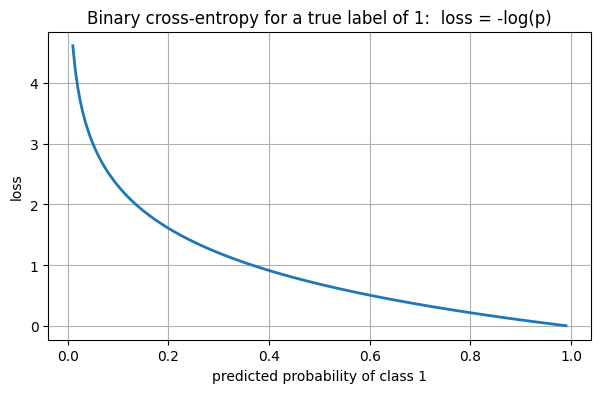

p =  0.9:  loss = 0.105
p =  0.5:  loss = 0.693
p =  0.1:  loss = 2.303
p = 0.01:  loss = 4.605


In [15]:
# How the loss behaves when the true label is 1: -log(p)
p_range = np.linspace(0.01, 0.99, 200)
plt.plot(p_range, -np.log(p_range), linewidth=2)
plt.title("Binary cross-entropy for a true label of 1:  loss = -log(p)")
plt.xlabel("predicted probability of class 1")
plt.ylabel("loss")
plt.show()

for prob in [0.9, 0.5, 0.1, 0.01]:
    print(f"p = {prob:>4}:  loss = {-np.log(prob):.3f}")

The loss climbs steeply as the predicted probability for the true class approaches 0. That steep slope gives a strong learning signal when the model is badly wrong.

## 4.3 Multi-class classification loss: categorical cross-entropy

With `K` classes the model outputs `K` probabilities from softmax. If the true class is `c`, the loss for that sample is `-log(p_c)`: only the probability given to the correct class matters.

Two label formats exist, and Keras has a loss for each:

* **One-hot labels** such as `[0, 1, 0]`: use `categorical_crossentropy`
* **Integer labels** such as `1`: use `sparse_categorical_crossentropy`

Both give identical numbers; only the label format differs.

In [16]:
# 3 samples, 3 classes. Rows are the model's softmax probabilities.
probs = np.array([
    [0.80, 0.10, 0.10],     # true class 0, confident and right
    [0.20, 0.70, 0.10],     # true class 1, fairly right
    [0.30, 0.30, 0.40],     # true class 2, unsure
])
labels_int = np.array([0, 1, 2])                 # integer labels
labels_onehot = np.eye(3)[labels_int]            # one-hot labels

per_sample = -np.log(probs[np.arange(3), labels_int])   # -log of probability of the true class
print("one-hot labels:\n", labels_onehot)
print("loss per sample :", per_sample)
print("mean loss (NumPy)          :", round(per_sample.mean(), 4))

cce = keras.losses.CategoricalCrossentropy()
scce = keras.losses.SparseCategoricalCrossentropy()
print("Keras categorical (one-hot):", round(float(cce(labels_onehot, probs)), 4))
print("Keras sparse (integers)    :", round(float(scce(labels_int, probs)), 4))

one-hot labels:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
loss per sample : [0.2231 0.3567 0.9163]
mean loss (NumPy)          : 0.4987
Keras categorical (one-hot): 0.4987
Keras sparse (integers)    : 0.4987


**Remember the pairing:**

* Regression: linear output + MSE or MAE
* Binary classification: sigmoid output + binary cross-entropy
* Multi-class (one correct class): softmax output + (sparse) categorical cross-entropy

A mismatch, such as sigmoid with MSE for classification, usually trains poorly.

In Keras you can also output raw scores (no softmax or sigmoid in the last layer) and set `from_logits=True` in the loss, which is slightly more numerically stable. For clarity, this notebook keeps the activation in the last layer.

---
# Part 5. The Keras workflow

Keras is a high-level library for building neural networks. Every project follows the same six steps:

1. **Prepare data:** load, split into train and test, scale features
2. **Build the model:** choose layers and activations
3. **Compile:** choose the optimiser, loss and metrics
4. **Fit (train):** choose epochs and batch size
5. **Evaluate:** measure performance on unseen test data
6. **Predict:** use the model on new data

### Keras terms used below

| Code | Meaning |
|---|---|
| `keras.Sequential([...])` | A model made of layers stacked one after another |
| `keras.Input(shape=(n,))` | Declares that each sample has `n` features. Always put it first. |
| `layers.Dense(units, activation=...)` | A fully connected layer with `units` neurons |
| `model.summary()` | Prints layers, output shapes and parameter counts |
| `model.compile(optimizer, loss, metrics)` | Configures how the model learns and what is reported |
| `model.fit(X, y, epochs, batch_size, validation_split, callbacks)` | Trains the model. Returns a `History` object holding loss per epoch. |
| `validation_split=0.2` | Hold back the last 20 percent of the training data for validation |
| `keras.callbacks.EarlyStopping(...)` | Stops training when the monitored value stops improving |
| `model.evaluate(X_test, y_test)` | Returns the loss and metrics on test data |
| `model.predict(X)` | Returns the model's outputs for new data |

### Reading the training log

During training, Keras prints lines such as

`Epoch 3/100` and `9/9 ... loss: 0.52 - val_loss: 0.55`

* `Epoch 3/100`: this is epoch 3 of a maximum of 100
* `9/9`: step 9 of 9 steps (batches) in this epoch, see the calculation in Part 2
* `loss`: average loss on the training batches in this epoch
* `val_loss`: loss on the held-out validation data at the end of the epoch

Compare `loss` and `val_loss`. If `loss` keeps falling but `val_loss` starts rising, the model is overfitting.

---
# Part 6. Example 1: Regression with Keras

**Goal:** predict a continuous number.

**Data:** the scikit-learn *diabetes* dataset. It has 442 patients, 10 baseline measurements (age, sex, body mass index, blood pressure and six blood serum values, already centred and scaled), and a target that measures disease progression one year later. It ships with scikit-learn, so no download is needed.

**Design choices:**

* Output layer: **1 neuron with linear activation** (the prediction can be any number)
* Loss: **mean squared error**; metric: **mean absolute error** (easy to interpret)
* Hidden layers: two dense layers with **ReLU**

## 6.1 Load and look at the data

In [17]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

data = load_diabetes(as_frame=True)
df = data.frame
print("shape:", df.shape)
df.head()

shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [18]:
print(df["target"].describe().round(2))
df.describe().T[["mean", "std", "min", "max"]].round(3)

count    442.00
mean     152.13
std       77.09
min       25.00
25%       87.00
50%      140.50
75%      211.50
max      346.00
Name: target, dtype: float64


,mean,std,min,max
age,-0.000,0.048,-0.107,0.111
sex,0.000,0.048,-0.045,0.051
bmi,-0.000,0.048,-0.090,0.171
bp,-0.000,0.048,-0.112,0.132
s1,-0.000,0.048,-0.127,0.154
s2,0.000,0.048,-0.116,0.199
s3,-0.000,0.048,-0.102,0.181
s4,-0.000,0.048,-0.076,0.185
s5,0.000,0.048,-0.126,0.134
s6,0.000,0.048,-0.138,0.136


## 6.2 Split and scale

* **Split:** 80 percent for training, 20 percent for the final test. `random_state` makes the split repeatable.
* **Scale:** neural networks train better when inputs and targets are on similar scales. We use `StandardScaler` (mean 0, standard deviation 1).
* **Important:** fit the scaler on the **training data only**, then apply it to the test data. Fitting on all data would leak information from the test set into training (data leakage).
* The target here ranges from about 25 to 346. Scaling it too keeps the loss values small and training smooth. We convert predictions back to the original units afterwards.

In [19]:
X = df.drop(columns="target").values
y = df["target"].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

x_scaler = StandardScaler().fit(X_train)       # learn mean and std from training data only
y_scaler = StandardScaler().fit(y_train)

X_train_s = x_scaler.transform(X_train)
X_test_s = x_scaler.transform(X_test)
y_train_s = y_scaler.transform(y_train)
y_test_s = y_scaler.transform(y_test)

print("train samples:", X_train_s.shape[0], "| test samples:", X_test_s.shape[0])
print("features per sample:", X_train_s.shape[1])

train samples: 353 | test samples: 89
features per sample: 10


## 6.3 Build the model

* `Input(shape=(10,))`: ten features per patient
* `Dense(32, activation="relu")`: 32 neurons, ReLU
* `Dense(16, activation="relu")`: 16 neurons, ReLU
* `Dense(1)`: one output neuron. No activation means linear, which is right for regression.

`keras.utils.set_random_seed(42)` makes the random weight initialisation repeatable.

In [20]:
keras.utils.set_random_seed(42)

reg_model = keras.Sequential([
    keras.Input(shape=(X_train_s.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1),                      # linear output for regression
], name="regression_model")

reg_model.summary()

Model: "regression_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 897 (3.50 KB)

 Trainable params: 897 (3.50 KB)

 Non-trainable params: 0 (0.00 B)

The parameter counts match the formula `(inputs + 1) * neurons`: `(10+1)*32 = 352`, `(32+1)*16 = 528`, `(16+1)*1 = 17`, total 897.

## 6.4 Compile

* `optimizer=keras.optimizers.Adam(learning_rate=0.001)`: Adam adapts the step size per weight; 0.001 is a common default
* `loss="mse"`: mean squared error
* `metrics=["mae"]`: also report mean absolute error

In [21]:
reg_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"],
)

## 6.5 Train

* `epochs=200`: an upper limit of 200 passes over the training data
* `batch_size=32`: update the weights after every 32 samples
* `validation_split=0.2`: 20 percent of the training data is held back to monitor `val_loss`
* `EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True)`: stop if `val_loss` has not improved for 20 epochs, then roll back to the best weights
* `verbose=0`: do not print a line per epoch (we will plot the history instead). Set `verbose=1` to see the `9/9` progress lines.

With 353 training samples and a 20 percent validation split, 282 samples are used to fit and 71 to validate, so each epoch has `ceil(282/32) = 9` steps.

In [22]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=20, restore_best_weights=True
)

history = reg_model.fit(
    X_train_s, y_train_s,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=0,
)

epochs_run = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print("epochs actually run :", epochs_run)
print("best epoch          :", best_epoch)
print("best val_loss       :", round(min(history.history["val_loss"]), 4))

epochs actually run : 91
best epoch          : 71
best val_loss       : 0.4769


## 6.6 Plot the learning curves

The `History` object stores the loss for each epoch. Plotting training and validation loss together is the main tool for spotting overfitting and underfitting.

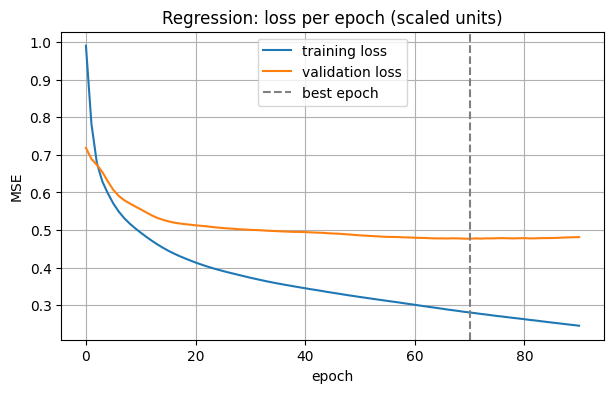

In [23]:
plt.plot(history.history["loss"], label="training loss")
plt.plot(history.history["val_loss"], label="validation loss")
plt.axvline(best_epoch - 1, color="gray", linestyle="--", label="best epoch")
plt.title("Regression: loss per epoch (scaled units)")
plt.xlabel("epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

**What to expect:** validation loss normally falls quickly, flattens, and may start to rise. Early stopping picks the weights at the flat bottom.

## 6.7 Evaluate on the unseen test set

We predict on the test set, convert predictions back to the original target units with `inverse_transform`, and report:

* **MAE:** average absolute error in target units
* **RMSE:** square root of MSE; penalises large errors more
* **R-squared:** share of the variation in the target explained by the model (1 is perfect, 0 is no better than predicting the mean)

We also compare against two baselines. A model is only useful if it beats simple alternatives.

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

pred_s = reg_model.predict(X_test_s, verbose=0)
pred = y_scaler.inverse_transform(pred_s)          # back to original units

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

# Baseline 1: always predict the training mean
mean_pred = np.full_like(y_test, y_train.mean())
# Baseline 2: ordinary linear regression
lin = LinearRegression().fit(X_train_s, y_train)
lin_pred = lin.predict(X_test_s)

results = pd.DataFrame({
    "MAE": [mean_absolute_error(y_test, mean_pred), mean_absolute_error(y_test, lin_pred), mae],
    "RMSE": [np.sqrt(mean_squared_error(y_test, mean_pred)), np.sqrt(mean_squared_error(y_test, lin_pred)), rmse],
    "R2": [r2_score(y_test, mean_pred), r2_score(y_test, lin_pred), r2],
}, index=["Predict the mean", "Linear regression", "Neural network"])
results.round(3)

,MAE,RMSE,R2
Predict the mean,64.006,73.222,-0.012
Linear regression,42.794,53.853,0.453
Neural network,42.250,53.463,0.461


Reading the table: the neural network should clearly beat "predict the mean". On a small tabular dataset like this, though, it often performs about the same as plain linear regression. That is normal and worth knowing: neural networks shine with large datasets and complex data such as images, text and audio, while simple models are often competitive on small tables.

## 6.8 Predicted versus actual

Points close to the diagonal line mean accurate predictions.

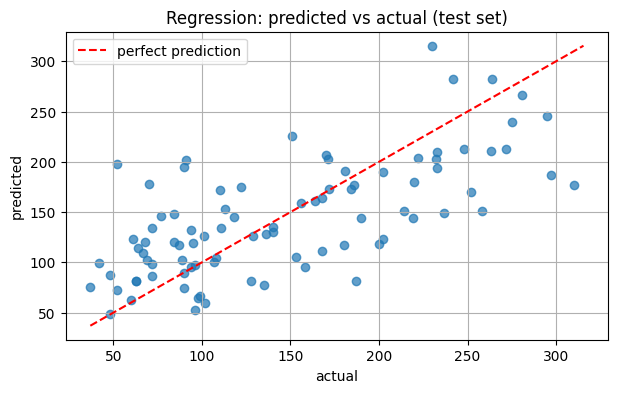

In [25]:
plt.scatter(y_test, pred, alpha=0.7)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--", label="perfect prediction")
plt.title("Regression: predicted vs actual (test set)")
plt.xlabel("actual")
plt.ylabel("predicted")
plt.legend()
plt.show()

## 6.9 Predict for a new patient

New data must go through the **same scaler** used for training. The output is scaled back to the original units.

In [26]:
new_patient = X_test[:1]                            # pretend this row is a new patient (unscaled)
new_scaled = x_scaler.transform(new_patient)
new_pred = y_scaler.inverse_transform(reg_model.predict(new_scaled, verbose=0))

print("predicted progression score:", round(float(new_pred[0, 0]), 1))
print("actual value               :", round(float(y_test[0, 0]), 1))

predicted progression score: 144.5
actual value               : 219.0


A single prediction can be well off the actual value. Judge the model by the test-set metrics in section 6.7, not by one example.

---
# Part 7. Example 2: Binary classification with Keras

**Goal:** predict one of two classes.

**Data:** the scikit-learn *breast cancer Wisconsin* dataset. It has 569 samples and 30 numeric measurements computed from images of cell nuclei (size, texture, smoothness and so on). The label is `0` for malignant and `1` for benign. It ships with scikit-learn.

**Design choices:**

* Output layer: **1 neuron with sigmoid activation**, giving the probability of class 1 (benign)
* Loss: **binary cross-entropy**
* Metrics: **accuracy** and **AUC** (area under the ROC curve: how well the model ranks positives above negatives, independent of any threshold)

This is for learning only and is not a medical tool.

## 7.1 Load and look at the data

In [27]:
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)
dfc = cancer.frame
print("shape:", dfc.shape)
print("class names:", {0: str(cancer.target_names[0]), 1: str(cancer.target_names[1])})
print()
print("class counts:")
print(dfc["target"].value_counts().rename({0: "malignant", 1: "benign"}))
dfc.iloc[:, :6].head()

shape: (569, 31)
class names: {0: 'malignant', 1: 'benign'}

class counts:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness
0,17.99,10.38,122.80,1001.0,0.11840,0.27760
1,20.57,17.77,132.90,1326.0,0.08474,0.07864
2,19.69,21.25,130.00,1203.0,0.10960,0.15990
3,11.42,20.38,77.58,386.1,0.14250,0.28390
4,20.29,14.34,135.10,1297.0,0.10030,0.13280


The classes are moderately imbalanced (more benign than malignant). That is why we use a **stratified** split below, which keeps the same class proportions in the training and test sets.

## 7.2 Split and scale

In [28]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

Xc = dfc.drop(columns="target").values
yc = dfc["target"].values

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    Xc, yc, test_size=0.2, random_state=42, stratify=yc
)

c_scaler = StandardScaler().fit(Xc_train)          # fit on training data only
Xc_train_s = c_scaler.transform(Xc_train)
Xc_test_s = c_scaler.transform(Xc_test)

print("train:", Xc_train_s.shape, "| test:", Xc_test_s.shape)
print("benign share in train:", round(yc_train.mean(), 3), "| in test:", round(yc_test.mean(), 3))

train: (455, 30) | test: (114, 30)
benign share in train: 0.626 | in test: 0.632


## 7.3 Build the model

* `Input(shape=(30,))`: thirty measurements per sample
* Two hidden `Dense` layers with ReLU
* `Dropout(0.2)`: during training, randomly switch off 20 percent of the neurons in the previous layer on each step. This discourages the network from relying on any single neuron and reduces overfitting. Dropout is automatically disabled at prediction time.
* `Dense(1, activation="sigmoid")`: outputs a probability between 0 and 1

In [29]:
keras.utils.set_random_seed(42)

clf_model = keras.Sequential([
    keras.Input(shape=(Xc_train_s.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),   # probability of class 1 (benign)
], name="binary_classifier")

clf_model.summary()

Model: "binary_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

## 7.4 Compile

* `loss="binary_crossentropy"`: the loss from Part 4
* `metrics=["accuracy", keras.metrics.AUC(name="auc")]`: accuracy uses a 0.5 threshold; AUC does not depend on a threshold

In [30]:
clf_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

## 7.5 Train

With 455 training samples, a 20 percent validation split leaves 364 for fitting. With `batch_size=16`, each epoch has `ceil(364/16) = 23` steps. Early stopping monitors `val_loss` with a patience of 15 epochs.

In [31]:
early_stop_c = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=15, restore_best_weights=True
)

hist_c = clf_model.fit(
    Xc_train_s, yc_train,
    epochs=150,
    batch_size=16,
    validation_split=0.2,
    callbacks=[early_stop_c],
    verbose=0,
)

best_epoch_c = int(np.argmin(hist_c.history["val_loss"])) + 1
print("epochs actually run:", len(hist_c.history["loss"]))
print("best epoch         :", best_epoch_c)
print("steps per epoch    :", math.ceil(364 / 16))

epochs actually run: 80
best epoch         : 65
steps per epoch    : 23


## 7.6 Plot the learning curves

Two panels: loss and accuracy, each for training and validation data.

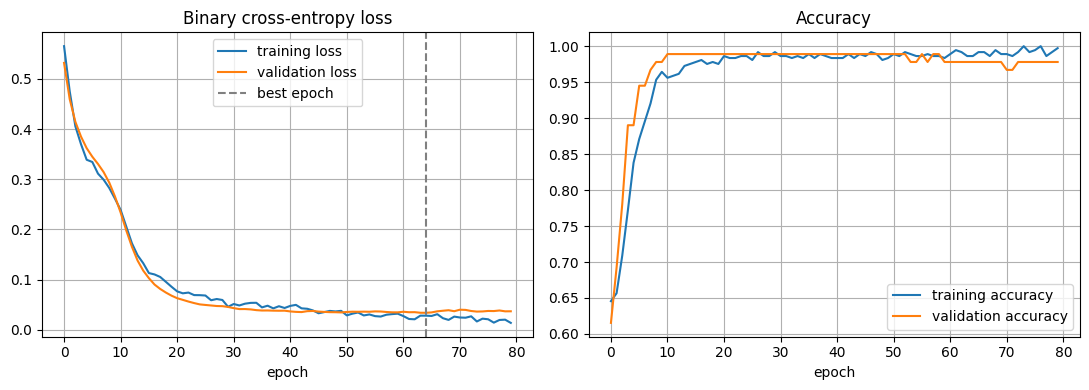

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(hist_c.history["loss"], label="training loss")
axes[0].plot(hist_c.history["val_loss"], label="validation loss")
axes[0].axvline(best_epoch_c - 1, color="gray", linestyle="--", label="best epoch")
axes[0].set_title("Binary cross-entropy loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].plot(hist_c.history["accuracy"], label="training accuracy")
axes[1].plot(hist_c.history["val_accuracy"], label="validation accuracy")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7.7 Evaluate on the unseen test set

`model.evaluate` returns the loss followed by each metric, in the order given to `compile`.

Then we turn probabilities into class labels with a **threshold** of 0.5: probability above 0.5 means class 1 (benign), otherwise class 0 (malignant).

In [33]:
test_loss, test_acc, test_auc = clf_model.evaluate(Xc_test_s, yc_test, verbose=0)
print(f"test loss    : {test_loss:.4f}")
print(f"test accuracy: {test_acc:.4f}")
print(f"test AUC     : {test_auc:.4f}")

test loss    : 0.0999
test accuracy: 0.9649
test AUC     : 0.9843


In [34]:
probs = clf_model.predict(Xc_test_s, verbose=0).ravel()    # probability of benign
preds = (probs >= 0.5).astype(int)                         # apply the 0.5 threshold

print("first 8 probabilities:", probs[:8].round(3))
print("first 8 predictions  :", preds[:8])
print("first 8 true labels  :", yc_test[:8])

first 8 probabilities: [0.    1.    0.001 0.235 0.    1.    1.    0.   ]
first 8 predictions  : [0 1 0 0 0 1 1 0]
first 8 true labels  : [0 1 0 1 0 1 1 0]


## 7.8 Confusion matrix and classification report

Accuracy alone can hide problems, especially with imbalanced classes. The **confusion matrix** counts each kind of right and wrong prediction.

| | Predicted malignant | Predicted benign |
|---|---|---|
| **Actually malignant** | correct | malignant missed (called benign) |
| **Actually benign** | benign flagged as malignant (false alarm) | correct |

* **Precision** for a class: of everything predicted as that class, how much was right
* **Recall** for a class: of everything that truly is that class, how much was found
* **F1** combines precision and recall

In [35]:
cm = confusion_matrix(yc_test, preds)
cm_df = pd.DataFrame(
    cm,
    index=["actual malignant", "actual benign"],
    columns=["predicted malignant", "predicted benign"],
)
print(cm_df)
print()
print(classification_report(yc_test, preds, target_names=["malignant", "benign"], digits=3))
print("ROC AUC (sklearn):", round(roc_auc_score(yc_test, probs), 4))

                  predicted malignant  predicted benign
actual malignant                   41                 1
actual benign                       3                69

              precision    recall  f1-score   support

   malignant      0.932     0.976     0.953        42
      benign      0.986     0.958     0.972        72

    accuracy                          0.965       114
   macro avg      0.959     0.967     0.963       114
weighted avg      0.966     0.965     0.965       114

ROC AUC (sklearn): 0.9914


## 7.9 The threshold is a choice

The 0.5 cut-off is a default, not a rule. In a screening setting, missing a malignant case (calling it benign) is usually far worse than a false alarm. Then you would require **higher confidence before predicting benign**, for example a threshold of 0.8. The next cell shows how the trade-off moves.

In [36]:
rows = []
for thr in [0.3, 0.5, 0.7, 0.8, 0.9]:
    pred_thr = (probs >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(yc_test, pred_thr).ravel()
    rows.append({
        "threshold": thr,
        "malignant missed (called benign)": fp,
        "benign flagged as malignant": fn,
        "accuracy": round((tn + tp) / len(yc_test), 3),
    })
pd.DataFrame(rows)

,threshold,malignant missed (called benign),benign flagged as malignant,accuracy
0,0.3,1,2,0.974
1,0.5,1,3,0.965
2,0.7,1,4,0.956
3,0.8,1,4,0.956
4,0.9,1,5,0.947


Compare the two error columns as the threshold rises. A higher threshold generally makes the model more cautious about saying "benign", so false alarms tend to rise, while missed malignant cases fall or stay flat. If the missed-malignant count barely changes, it means the model's probabilities are mostly very close to 0 or 1, so few samples sit near the cut-off. A less confident model would show a bigger effect.

Choosing the threshold is a decision about the cost of each type of error. It is not something the model decides for you.

## 7.10 Predict for a new sample

In [37]:
sample = Xc_test[:1]                                     # one unscaled sample
sample_s = c_scaler.transform(sample)                    # same scaler as training
p_benign = float(clf_model.predict(sample_s, verbose=0)[0, 0])

print(f"probability benign   : {p_benign:.3f}")
print("predicted class      :", cancer.target_names[int(p_benign >= 0.5)])
print("actual class         :", cancer.target_names[int(yc_test[0])])

probability benign   : 0.000
predicted class      : malignant
actual class         : malignant


---
# Part 8. Adapting the pattern to multi-class classification

You have now seen the full pattern twice. For a problem with `K` classes (for example 10 digits), only three things change compared with the binary example:

```python
# 1. Output layer: K neurons with softmax
layers.Dense(K, activation="softmax")

# 2. Loss: use sparse labels (integers 0..K-1) or one-hot labels
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # integer labels
    # loss="categorical_crossentropy",        # one-hot labels instead
    metrics=["accuracy"],
)

# 3. Predictions: pick the class with the highest probability
predicted_class = model.predict(X).argmax(axis=1)
```

Everything else (splitting, scaling, validation split, early stopping, plotting history) stays the same.

---
# Part 9. Summary and cheat sheet

| Task | Output layer | Loss | Metrics |
|---|---|---|---|
| Regression | `Dense(1)` (linear) | `mse`, `mae`, `huber` | MAE, RMSE, R-squared |
| Binary classification | `Dense(1, activation="sigmoid")` | `binary_crossentropy` | accuracy, AUC, precision, recall |
| Multi-class classification | `Dense(K, activation="softmax")` | `sparse_categorical_crossentropy` or `categorical_crossentropy` | accuracy |
| Multi-label classification | `Dense(K, activation="sigmoid")` | `binary_crossentropy` | per-label precision and recall |

Hidden layers: start with `Dense(..., activation="relu")`.

**Good habits shown in this notebook**

* Split data into training and test sets first; scale using training data only
* Use a validation split and early stopping to control overfitting
* Plot training and validation loss every time
* Compare against a simple baseline before trusting a neural network
* Report test results only once, at the end

**Connection to Generative AI:** language models minimise multi-class cross-entropy over a vocabulary, GAN discriminators minimise binary cross-entropy, and diffusion models minimise a regression loss. The ideas in this notebook are the foundation of those systems.

## Exercises

1. In Part 6, change the hidden layers to `Dense(8)` only, then to `Dense(128)` twice. How do the learning curves and test MAE change? Which looks underfit, which looks overfit?
2. Change `learning_rate` to `0.1` and then to `0.00001`. Describe what happens to the loss curve.
3. Set `batch_size=8`, then `batch_size=256`. How many steps per epoch does each give, and how does training behave?
4. Replace `"mse"` with `"mae"` in the regression compile step. Does the test MAE improve?
5. In Part 7, remove the `Dropout` layer and compare validation loss with and without it.
6. Use the iris dataset (`sklearn.datasets.load_iris`) to build a multi-class model using the pattern in Part 8.

## Further reading

* Keras documentation: guides on the Sequential model, training and evaluation, and callbacks
* Michael Nielsen, *Neural Networks and Deep Learning* (free online book)
* 3Blue1Brown, neural network video series
* Goodfellow, Bengio and Courville, *Deep Learning*